# Stage 1 — Independent Relevance Review and Graph Validation

This supplementary notebook implements the Stage 1 feedback before the Stage 3 evidence selection. It reuses the submitted notebook's exports; it does not rerun cleaning, NER, NMF or model training.

The feedback asks for independent article relevance checks, verification of important semantic edges, and reliable links between the co-occurrence and semantic graphs. Four outputs address these requests:

1. A reproducible source-based article review with known sampling probabilities.
2. A source-alignment audit and a separately preserved semantic-relation review.
3. A canonical entity/article index and a retrieval graph with explicit evidence types.
4. A dated, fingerprinted handoff manifest that discloses review methods and unresolved cases.

**Automated alignment is not factual correctness.** Source judgments may be human or AI-assisted, as explicitly recorded in `review_method`. The user requested an AI-assisted source review after the initial blank templates were created. These judgments are based on article evidence, not copied from tags, NMF topics or classifier scores; they are not human ground truth. Existing Stage 1 and Stage 2 artifacts remain inputs. The original 40-edge review was reported only as aggregate prose, so it cannot be transferred to individual edges without new source-linked decisions.


## 1. Inputs and reproducible scope

The official corpus period is **1 September 2024 to 31 August 2026**. Stage 1's full corpus includes later articles; this notebook reports and excludes them from the handoff. Dates are article publication dates, not verified event or legal-effective dates.

Source-review annotations are stored in `data/processed/validation/stage1/`. Technical exports are stored in `outputs/validation/stage1/`. Rerunning refreshes source metadata and preserves the explicitly editable review columns. If a reviewed source changes or its row leaves the sample, execution stops instead of silently reusing or losing the decision. Archive the old review CSV explicitly before intentionally resampling.


In [1]:
from pathlib import Path
import json
import sys

import networkx as nx
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, Markdown

PROJECT_ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents]
                    if (p / "notebooks/stage1_ai_governance/Stage1_AI_Governance.ipynb").exists())
if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

from src.stage1_validation.common import (
    load_stage1_normalization, sha256_file, write_review_packet,
)
from src.stage1_validation.articles import (
    prepare_article_review, summarize_article_review, apply_article_review,
)
from src.stage1_validation.graphs import (
    audit_relations, prepare_relation_review, summarize_relation_review,
    build_entity_links, build_retrieval_graph, supporting_articles,
)

SEED = 42
START, END = "2024-09-01", "2026-08-31"
ARTICLE_SAMPLE_SIZE, CANDIDATE_SAMPLE_SIZE, RELATION_SAMPLE_SIZE = 120, 40, 40
REVIEW_DIR = PROJECT_ROOT / "data/processed/validation/stage1"
OUTPUT_DIR = PROJECT_ROOT / "outputs/validation/stage1"
REVIEW_DIR.mkdir(parents=True, exist_ok=True)
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

INPUTS = {
    "corpus": PROJECT_ROOT / "data/processed/corpus/ai_media_clean.pkl.gz",
    "entities": PROJECT_ROOT / "data/processed/entities/governance_entities_normalized.pkl",
    "topics": PROJECT_ROOT / "data/processed/topics/ai_governance_topic_assignments.csv",
    "candidates": PROJECT_ROOT / "outputs/results/stage2/candidate_theme_predictions_selected_model.csv",
    "co_graph": PROJECT_ROOT / "outputs/knowledge_graph/ai_governance_knowledge_graph_enriched.graphml",
    "relations": PROJECT_ROOT / "outputs/knowledge_graph/ai_governance_extracted_relations.csv",
    "schema": PROJECT_ROOT / "outputs/knowledge_graph/ai_governance_knowledge_graph_schema.json",
    "stage1_notebook": PROJECT_ROOT / "notebooks/stage1_ai_governance/Stage1_AI_Governance.ipynb",
}
missing = [str(path.relative_to(PROJECT_ROOT)) for path in INPUTS.values() if not path.exists()]
if missing:
    raise FileNotFoundError("Required local Stage 1/2 exports are missing: " + ", ".join(missing))


In [2]:
corpus = pd.read_pickle(INPUTS["corpus"])
entities = pd.read_pickle(INPUTS["entities"])
topics = pd.read_csv(INPUTS["topics"])
candidates = pd.read_csv(INPUTS["candidates"])
relations = pd.read_csv(INPUTS["relations"])
co_graph = nx.read_graphml(INPUTS["co_graph"])
schema = json.loads(INPUTS["schema"].read_text())
aliases, type_overrides = load_stage1_normalization(INPUTS["stage1_notebook"])

assert corpus["record_id"].is_unique
assert entities["record_id"].is_unique
assert set(entities["record_id"]).issubset(set(corpus["record_id"]))
in_window = pd.to_datetime(corpus["date"]).between(START, END)
scope_summary = pd.DataFrame({
    "Articles": [len(corpus), int(in_window.sum()), int((~in_window).sum())],
    "Tagged Governance": [int(corpus["governance_related"].sum()),
                          int(corpus.loc[in_window, "governance_related"].sum()),
                          int(corpus.loc[~in_window, "governance_related"].sum())],
}, index=["Original Stage 1", "Official period", "Excluded outside period"])
display(scope_summary)


,Articles,Tagged Governance
Original Stage 1,47679,12946
Official period,47438,12859
Excluded outside period,241,87


## 2. Independent article relevance review

The primary sample contains **120 originally tagged Governance articles**. Its strata are a disjoint, rare-first primary theme (Regulation, Bias/Fairness, Security, Accountability) crossed with four six-month periods. Within each stratum, selection is uniform without replacement. Every nonempty stratum receives at least one article; remaining slots are allocated proportionally. The saved stratum populations and inverse inclusion weights permit a design-weighted relevance-rate estimate after the entire primary sample is resolved.

A separate random sample of **40 untagged Stage 2 candidates** checks obvious candidate-selection failures. It is not mixed into the primary estimate, does not estimate corpus recall, and does not add articles to Stage 1 or Stage 2 automatically. The candidate filename identifies the current validation-selected model rather than the older Qwen-only export.

Coverage tables show sources, months, overlapping Governance dimensions and NMF topics. Sources and individual months are coverage diagnostics, not additional sampling strata. The eight NMF topics remain exploratory; business, marketing and source-specific job-ad language do not independently establish Governance relevance.


In [3]:
article_review, sampling_plan, coverage = prepare_article_review(
    corpus, topics, candidates, REVIEW_DIR / "article_review.csv",
    seed=SEED, sample_size=ARTICLE_SAMPLE_SIZE,
    candidate_sample_size=CANDIDATE_SAMPLE_SIZE, start=START, end=END,
)
display(sampling_plan)
display(coverage.loc[(coverage["sample_group"] == "tagged_stratified") &
                     coverage["dimension"].isin(["theme", "nmf_topic"])])
write_review_packet(article_review, OUTPUT_DIR / "article_review_sources.html", kind="article")
print("Editable review:", REVIEW_DIR / "article_review.csv")
print("Tag-blind reading packet:", OUTPUT_DIR / "article_review_sources.html")


Editable review: /Users/henrik/Documents/CTL/data/processed/validation/stage1/article_review.csv
Tag-blind reading packet: /Users/henrik/Documents/CTL/outputs/validation/stage1/article_review_sources.html


,sample_group,stratum,population_size,sample_size,inclusion_probability,sample_weight
0,tagged_stratified,accountability|period_0,861,8,0.009292,107.625000
1,tagged_stratified,accountability|period_1,1217,11,0.009039,110.636364
2,tagged_stratified,accountability|period_2,1310,12,0.009160,109.166667
3,tagged_stratified,accountability|period_3,2121,18,0.008487,117.833333
4,tagged_stratified,bias_fairness|period_0,512,5,0.009766,102.400000
5,tagged_stratified,bias_fairness|period_1,616,6,0.009740,102.666667
6,tagged_stratified,bias_fairness|period_2,599,6,0.010017,99.833333
7,tagged_stratified,bias_fairness|period_3,637,6,0.009419,106.166667
8,tagged_stratified,regulation|period_0,297,3,0.010101,99.000000
9,tagged_stratified,regulation|period_1,323,4,0.012384,80.750000


,sample_group,dimension,value,population_count,sample_count
35,tagged_stratified,nmf_topic,"Business, Markets & Investment",2715,27
36,tagged_stratified,nmf_topic,Geopolitics & Public Policy,2454,20
37,tagged_stratified,nmf_topic,"LLMs, Model Training & Safety",2091,21
38,tagged_stratified,nmf_topic,"Data Governance, Privacy & Compliance",1643,18
39,tagged_stratified,nmf_topic,"Search, Digital Media & Marketing",1327,10
40,tagged_stratified,nmf_topic,"AI Agents, MCP & Enterprise Tooling",1217,9
41,tagged_stratified,nmf_topic,Cybersecurity & Cloud Security,1146,14
42,tagged_stratified,nmf_topic,Software Engineering & DevSecOps,266,1
43,tagged_stratified,theme,security,4431,41
44,tagged_stratified,theme,accountability,7540,74


### Review protocol and provenance

Open the HTML reading packet and edit only these columns in `article_review.csv`:

| Column | Required decision |
|---|---|
| `relevance_verdict` | `relevant`, `irrelevant`, `uncertain`, or blank while pending |
| `review_method` | `human` or `ai_assisted`; required with a verdict |
| `reviewer` | Actual reviewer identity; AI reviews use `ChatGPT / Codex` |
| `review_evidence` | For `relevant`, an exact quote supporting substantive AI Governance content |
| `review_notes` | Explanation; required for `irrelevant` or `uncertain` |
| `reviewed_at` | Review date, recommended in ISO format |

**Relevant:** AI security/safety, accountability, fairness/bias or AI regulation is a substantive part of the article. A practical technical discussion can qualify when it explicitly connects its content to these concerns. **Irrelevant:** incidental keywords, ordinary software/business/marketing coverage, job advertisements or generic security/privacy boilerplate without substantive AI Governance content. **Uncertain:** the available source does not support a confident decision. Judge the source independently of its tags or topic label; the reading packet omits those labels.

Use uncertainty instead of guessing. Discuss uncertain cases in the team, preserving the final rationale. Quotes establish a source reference; they do not automatically make a judgment correct. The notebook validates the review's structure, not the reviewer's reasoning.


In [4]:
article_summary, topic_review = summarize_article_review(article_review)
eligible_articles = apply_article_review(corpus, article_review, start=START, end=END)
display(article_summary)
display(topic_review)
print(f"Eligible tagged articles after date and explicit rejection checks: {len(eligible_articles):,}")
print("Unreviewed/uncertain sources remain visibly weak-labelled, not independently validated.")


Eligible tagged articles after date and explicit rejection checks: 12,807
Unreviewed/uncertain sources remain visibly weak-labelled, not independently validated.


,sample_group,sample_size,reviewed,resolved,pending,uncertain,relevant,irrelevant,human_reviewed,ai_reviewed,review_completion,main_sample_complete,main_human_sample_complete,weighted_relevance_min,weighted_relevance_max,weighted_precision
0,stage2_candidates,40,40,38,0,2,22,16,0,40,1.0,False,False,NaN,NaN,NaN
1,tagged_stratified,120,120,118,0,2,66,52,0,120,1.0,False,False,0.545254,0.562674,NaN


,dominant_topic_label,sample_size,reviewed,resolved,pending,uncertain,relevant,irrelevant,weighted_relevance_min,weighted_relevance_max,weighted_precision
0,"AI Agents, MCP & Enterprise Tooling",9,9,9,0,0,5,4,0.531727,0.531727,NaN
1,"Business, Markets & Investment",27,27,26,0,1,12,14,0.435880,0.477005,NaN
2,Cybersecurity & Cloud Security,14,14,14,0,0,10,4,0.715922,0.715922,NaN
3,"Data Governance, Privacy & Compliance",18,18,17,0,1,11,6,0.605668,0.661680,NaN
4,Geopolitics & Public Policy,20,20,20,0,0,9,11,0.447339,0.447339,NaN
5,"LLMs, Model Training & Safety",21,21,21,0,0,14,7,0.661338,0.661338,NaN
6,"Search, Digital Media & Marketing",10,10,10,0,0,5,5,0.505137,0.505137,NaN
7,Software Engineering & DevSecOps,1,1,1,0,0,0,1,0.000000,0.000000,NaN


## 3. Semantic edge evidence and attributed source review

The original extraction input was `(title + ". " + content_text)[:3000]`. Its offsets refer to that composite text. Merely having `char_start` is insufficient to prove grounding. The audit separately checks source existence, publication-date agreement, schema membership, exact offset equality, exact quote occurrence and unique recoverability.

An exact quote may be re-anchored if it occurs once in the source; repeated quotes require explicit matching offsets. A paraphrase or ellipsis cannot pass as an exact quotation. None of these checks establishes that the cited text actually states the proposed relation.

The review selects 20 important edges using graph prominence and Governance-related predicates, followed by 20 uniformly random edges from the remainder. This mixed priority sample is a diagnostic, not an unbiased estimate of the full graph's factual precision. The original aggregate finding (29 supported, 6 weak, 5 incorrect out of 40) is retained as context and is not fabricated as row-level annotations.


In [5]:
relation_audit = audit_relations(relations, corpus, schema, aliases, type_overrides)
relation_review = prepare_relation_review(
    relation_audit, co_graph, REVIEW_DIR / "relation_review.csv",
    sample_size=RELATION_SAMPLE_SIZE, seed=SEED,
)
relation_summary = summarize_relation_review(
    relation_audit, relation_review, eligible_articles=eligible_articles
)
display(relation_summary)
# All boolean audit columns are reported; alignment rates never stand in for factual precision.
audit_checks = relation_audit.select_dtypes(include="bool").sum().rename("Passing rows").to_frame()
audit_checks["Total relations"] = len(relation_audit)
display(audit_checks)
write_review_packet(relation_review, OUTPUT_DIR / "relation_review_sources.html", kind="relation")
print("Editable review:", REVIEW_DIR / "relation_review.csv")
print("Reading packet:", OUTPUT_DIR / "relation_review_sources.html")


Editable review: /Users/henrik/Documents/CTL/data/processed/validation/stage1/relation_review.csv
Reading packet: /Users/henrik/Documents/CTL/outputs/validation/stage1/relation_review_sources.html


,relations_available,sampled_relations,resolved_reviews,pending_or_unresolved_reviews,important_relations,important_pending_or_unresolved,supported_exact_source_in_sample,human_reviewed,ai_reviewed,human_review_complete,review_complete
0,162,40,40,0,20,0,22,0,40,False,True


,Passing rows,Total relations
source_found,162,162
source_date_matches,162,162
schema_valid,141,162
exact_span_match,127,162
evidence_in_input,132,162
evidence_in_source,132,162


### How to review a relation

Edit the following columns in `relation_review.csv`. The reading packet supplies the original triple, its quoted evidence and the complete article source.

| Column | Required decision |
|---|---|
| `relation_verdict` | `supported`, `weak`, `incorrect`, `uncertain`, or blank while pending |
| `review_method` | `human` or `ai_assisted`; required with a verdict |
| `reviewer` | Actual reviewer identity; AI reviews use `ChatGPT / Codex` |
| `review_notes` | Explain the relation type, direction and support, especially a rejection |
| `reviewed_evidence` | Optional replacement **exact** quote when the original evidence is unsuitable |
| `reviewed_char_start`, `reviewed_char_end` | Optional positions in full `title + ". " + content_text`; needed to disambiguate repeated quotes |
| `reviewed_at` | Required review date in valid ISO format (`YYYY-MM-DD`) |

`Supported` means that the source explicitly supports the complete triple and direction. Mere co-mention, a law's name in a list, a proposal presented as an adopted law, or a plausible fact from outside the article does not qualify. `Weak` and `incorrect` exclude the edge from factual retrieval; `uncertain` remains unresolved. Incorrect triples are rejected rather than silently corrected. A later corrected extraction needs its own source-linked record and review.

Only supported reviews with a reviewer, valid source/date/schema, eligible source article and an exact unambiguous evidence span may enter the semantic layer of the exported graph. Neither a human nor an AI-assisted verdict can override a failed provenance check.


## 4. Link graphs to source articles

The original aliases and type overrides are read as literal dictionaries from the submitted notebook without executing its cells. Entity IDs remain `TYPE::NAME`. Matching uses explicit aliases/overrides and unique case-insensitive matches within the same type. Conflicting types are reported, never merged by fuzzy name similarity. Relation-only nodes remain available even when frequency thresholds kept them out of the co-occurrence graph.

The entity/article index records NER-backed membership, publication date, source fingerprint and article-review status. Co-occurrence evidence is the intersection of the two endpoint article sets; theme evidence additionally checks the article's tag-derived theme. Counts are recomputed after the official date restriction and explicit article rejections. An association remains an association, even when many articles support it.

The retrieval graph uses a `MultiDiGraph` so multiple semantic statements and source articles remain distinct. Undirected associations are represented in both directions with `direction="undirected"` and `fact_assertion=False`. Accepted semantic edges alone assert reviewed source statements and disclose whether their review was human or AI-assisted. Their source article and exact evidence remain directly attached, including for low-frequency entities absent from the NER index.


In [6]:
entity_mapping, entity_articles, link_summary = build_entity_links(
    co_graph, relation_audit, entities, eligible_articles, aliases, type_overrides,
)
retrieval_graph, edge_audit = build_retrieval_graph(
    co_graph, relation_audit, relation_review, entity_mapping,
    entity_articles, eligible_articles, schema,
)
display(link_summary)
display(entity_mapping.head(10))
display(edge_audit.head(10))
print(f"Retrieval graph: {retrieval_graph.number_of_nodes():,} nodes, "
      f"{retrieval_graph.number_of_edges():,} directed storage edges")


Retrieval graph: 855 nodes, 14,226 directed storage edges


,cooccurrence_entity_ids,semantic_entity_ids,shared_entity_ids,semantic_only_entity_ids,type_conflict_names,entity_article_memberships,indexed_articles
0,724,172,41,131,290,138708,12745


,original_id,canonical_id,match_method,origins,in_cooccurrence_graph,in_relation_graph,type_conflict,conflicting_types
0,GPE::AI Overviews,GPE::AI Overviews,exact,ner_cache,False,False,True,GPE;ORG
1,GPE::AL,GPE::AL,exact,ner_cache,False,False,True,GPE;ORG;PERSON
2,GPE::ATLANTA,GPE::Atlanta,exact+unique_same_type_casefold,ner_cache,True,False,False,GPE
3,GPE::AUSTIN,GPE::Austin,exact+unique_same_type_casefold,ner_cache,True,False,True,GPE;PERSON
4,GPE::Accenture,GPE::Accenture,exact,ner_cache,False,False,True,GPE;ORG;PERSON
5,GPE::Afghanistan,GPE::Afghanistan,exact,cooccurrence_graph;ner_cache,True,False,False,GPE
6,GPE::Al,GPE::Al,exact,ner_cache,False,False,True,GPE;ORG;PERSON
7,GPE::Alaska,GPE::Alaska,exact,cooccurrence_graph;ner_cache,True,False,False,GPE
8,GPE::Alibaba,GPE::Alibaba,exact,cooccurrence_graph;ner_cache,True,False,False,GPE
9,GPE::Alphabet,GPE::Alphabet,exact,ner_cache,False,False,True,GPE;ORG;PERSON


,edge_kind,source,target,predicate,original_weight,current_support,included,decision_reason,relation_id,record_id,relation_verdict,review_method,review_recorded,review_complete,eligible_for_factual_retrieval,effective_evidence,effective_char_start,effective_char_end,anchor_method,reviewer,reviewed_at
0,association,TECHNOLOGY::Artificial Intelligence,GPE::United States,CO_MENTIONED_WITH,3775.0,3730.0,True,dated_ner_support,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,association,TECHNOLOGY::Artificial Intelligence,ORG::Google,CO_MENTIONED_WITH,2058.0,2044.0,True,dated_ner_support,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,association,TECHNOLOGY::Artificial Intelligence,ORG::OpenAI,CO_MENTIONED_WITH,1780.0,1765.0,True,dated_ner_support,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
3,association,TECHNOLOGY::Artificial Intelligence,TECHNOLOGY::API,CO_MENTIONED_WITH,1482.0,1464.0,True,dated_ner_support,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
4,association,TECHNOLOGY::Artificial Intelligence,ORG::Microsoft,CO_MENTIONED_WITH,1420.0,1416.0,True,dated_ner_support,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
5,association,TECHNOLOGY::Artificial Intelligence,TECHNOLOGY::Large Language Model,CO_MENTIONED_WITH,1287.0,1280.0,True,dated_ner_support,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
6,association,TECHNOLOGY::Artificial Intelligence,GPE::China,CO_MENTIONED_WITH,1219.0,1209.0,True,dated_ner_support,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
7,association,TECHNOLOGY::Artificial Intelligence,GPE::United Kingdom,CO_MENTIONED_WITH,1150.0,1140.0,True,dated_ner_support,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
8,association,TECHNOLOGY::Artificial Intelligence,PERSON::Trump,CO_MENTIONED_WITH,1030.0,1018.0,True,dated_ner_support,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
9,association,TECHNOLOGY::Artificial Intelligence,ORG::European Union,CO_MENTIONED_WITH,886.0,878.0,True,dated_ner_support,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


In [7]:
# Demonstrate source retrieval for one strong co-occurrence association.
associations = [(u, v, data) for u, v, data in retrieval_graph.edges(data=True)
                if data.get("relation") == "CO_MENTIONED_WITH"]
if associations:
    left, right, attributes = max(associations, key=lambda item: item[2].get("weight", 0))
    source_rows = supporting_articles(entity_articles, left, right)
    print(left, "<->", right, "| supporting articles:", len(source_rows))
    display(source_rows.head(5))
else:
    print("No co-occurrence associations survive the current scope/review policy.")


TECHNOLOGY::Artificial Intelligence <-> GPE::United States | supporting articles: 3730


,record_id,date,source_fingerprint,article_review_status,article_review_method,source
0,3,2025-04-24,fc30bf26e19f16b9728cb4b96db02b93de904ad6615c29...,unreviewed,unreviewed,ner
1,158,2025-02-21,5456cf6257b1c8566cd0c8526d09e4d23d186ad18dd020...,unreviewed,unreviewed,ner
2,174,2025-01-27,b4e1d077668736e030fc80a5b6486536877b6a8a46e795...,unreviewed,unreviewed,ner
3,746,2024-10-26,dc47a310b21f57b06a30165c60b681e0fdfa1ac732a00f...,unreviewed,unreviewed,ner
4,797,2025-06-25,48c9bf0bcecdb3e4d05e79bab8bf1dcf63b2ebf23054fd...,unreviewed,unreviewed,ner


## 5. Export and Stage 3 handoff

The exports preserve three separate meanings: NER/article membership, weighted co-occurrence/theme association, and source-reviewed explicit semantic relations with review-method attribution. `relation_edge_audit.csv` records why each extracted relation is included or excluded. Unreviewed semantic relations are excluded. Accepted AI-assisted relations retain `review_method="ai_assisted"` and corresponding graph provenance; they never become human-reviewed facts.

The manifest separates source-review completion from `human_review_complete`. The weighted relevance bounds assign uncertain labels first all irrelevant, then all relevant; they are **not statistical confidence intervals**. AI-assisted completion is reported as `ai_reviewed` or `ai_reviewed_with_unresolved_cases`, not human validation. It does not certify every article or the full graph. Before Stage 3 passage selection, inspect the weighted primary-sample relevance rate, topic-specific failures, uncertain cases and rejected semantic relations. The measured relevance failures document a limitation of the existing tag selection. The requested feedback work consists of sample validation, edge checks and reliable graph linkage; a corpus-wide relevance-filter redesign would be separate work. Additional Stage 2 candidates remain a separate diagnostic until independently justified.

Stage 3 should use `entity_articles.csv.gz` to resolve graph anchors to original source articles and its own chunks. Every chunk should carry its original `record_id`, publication date, source fingerprint and original-text offsets. Lemmatized text and NMF topics are not factual evidence. Time-aware answers must distinguish article publication time from the event described.


In [8]:
# Small review/diagnostic tables are versionable; the article index is compressed.
article_summary.to_csv(OUTPUT_DIR / "article_review_summary.csv", index=False)
topic_review.to_csv(OUTPUT_DIR / "article_review_by_nmf_topic.csv", index=False)
sampling_plan.to_csv(OUTPUT_DIR / "article_sampling_plan.csv", index=False)
coverage.to_csv(OUTPUT_DIR / "article_sample_coverage.csv", index=False)
scope_summary.to_csv(OUTPUT_DIR / "corpus_scope_summary.csv")
relation_summary.to_csv(OUTPUT_DIR / "relation_review_summary.csv", index=False)
relation_audit.drop(columns=["content_text", "source_text", "full_source_text"], errors="ignore").to_csv(
    OUTPUT_DIR / "relation_evidence_audit.csv", index=False)
edge_audit.to_csv(OUTPUT_DIR / "relation_edge_audit.csv", index=False)
entity_mapping.to_csv(OUTPUT_DIR / "entity_mapping.csv", index=False)
entity_articles.to_csv(OUTPUT_DIR / "entity_articles.csv.gz", index=False, compression="gzip")
link_summary.to_csv(OUTPUT_DIR / "graph_link_summary.csv", index=False)
eligible_articles[["record_id", "date", "source_fingerprint", "article_review_status", "article_review_method"]].to_csv(
    OUTPUT_DIR / "eligible_articles.csv", index=False)
nx.write_graphml(retrieval_graph, OUTPUT_DIR / "audited_retrieval_graph.graphml")

main_progress = article_summary.loc[article_summary["sample_group"].eq("tagged_stratified")].iloc[0]
article_complete = bool(main_progress["main_sample_complete"])
# The summary validates reviewer/date, exact evidence and source eligibility, not just verdict strings.
verdicts = relation_review["relation_verdict"].fillna("").astype(str).str.strip()
relation_complete = bool(relation_summary.iloc[0]["review_complete"])
semantic_facts = [(u, v, d) for u, v, d in retrieval_graph.edges(data=True)
                  if bool(d.get("fact_assertion", False))]
assert all(d.get("record_id") is not None and d.get("evidence") for _, _, d in semantic_facts)
required_reviews_complete = article_complete and relation_complete
human_complete = bool(main_progress["main_human_sample_complete"]) and bool(relation_summary.iloc[0]["human_review_complete"])
all_recorded = bool(int(main_progress["reviewed"]) == ARTICLE_SAMPLE_SIZE and
                    int(relation_summary.iloc[0]["human_reviewed"] + relation_summary.iloc[0]["ai_reviewed"]) == RELATION_SAMPLE_SIZE)
manifest = {
    "version": 2,
    "status": (
        "human_review_complete" if human_complete else
        "ai_reviewed" if all_recorded and required_reviews_complete else
        "ai_reviewed_with_unresolved_cases" if all_recorded else "pending_review"
    ),
    "human_review_complete": human_complete,
    "all_required_source_reviews_recorded": all_recorded,
    "review_methods": sorted(set(article_review.loc[article_review["relevance_verdict"].ne(""), "review_method"]) |
                             set(relation_review.loc[relation_review["relation_verdict"].ne(""), "review_method"])),
    "required_reviews_complete": required_reviews_complete,
    "scope": {"publication_start": START, "publication_end": END},
    "sampling": {"seed": SEED, "primary_articles": ARTICLE_SAMPLE_SIZE,
                 "diagnostic_candidates": CANDIDATE_SAMPLE_SIZE, "relations": RELATION_SAMPLE_SIZE},
    "counts": {"eligible_tagged_articles": len(eligible_articles),
               "primary_article_reviews_resolved": int(main_progress["resolved"]),
               "relation_reviews_resolved": int(relation_summary.iloc[0]["resolved_reviews"]),
               "retrieval_nodes": retrieval_graph.number_of_nodes(),
               "retrieval_storage_edges": retrieval_graph.number_of_edges(),
               "reviewed_semantic_facts": len(semantic_facts),
               "primary_human_reviews": int(main_progress["human_reviewed"]),
               "primary_ai_reviews": int(main_progress["ai_reviewed"]),
               "relation_human_reviews": int(relation_summary.iloc[0]["human_reviewed"]),
               "relation_ai_reviews": int(relation_summary.iloc[0]["ai_reviewed"])},
    "design_weighted_primary_relevance_rate": (
        float(main_progress["weighted_precision"]) if article_complete else None),
    "relevance_assessment_method": "AI-assisted source judgment unless a row explicitly records human review",
    "relevance_bounds_definition": "uncertain labels assigned all irrelevant/all relevant; not a confidence interval",
    "weighted_relevance_bounds_if_uncertain": (
        [float(main_progress["weighted_relevance_min"]), float(main_progress["weighted_relevance_max"])]
        if int(main_progress["reviewed"]) == ARTICLE_SAMPLE_SIZE else None),
    "policy": {"human_reviews_fabricated": False, "unreviewed_semantic_facts_allowed": False,
               "candidate_articles_automatically_added": False,
               "unreviewed_article_relevance": "weak dataset labels, not validated",
               "cooccurrence": "association only; original article evidence via index intersection",
               "review_quote_offsets": "full title + '. ' + content_text",
               "readiness_meaning": "attributed source review only; AI judgments are not human ground truth"},
    "inputs_sha256": {name: sha256_file(path) for name, path in INPUTS.items()},
    "review_sha256": {name: sha256_file(REVIEW_DIR / name)
                      for name in ["article_review.csv", "relation_review.csv"]},
    "code_sha256": {path.name: sha256_file(path)
                    for path in sorted((PROJECT_ROOT / "src/stage1_validation").glob("*.py"))},
    "artifacts": {"graph": "outputs/validation/stage1/audited_retrieval_graph.graphml",
                  "entity_articles": "outputs/validation/stage1/entity_articles.csv.gz",
                  "entity_mapping": "outputs/validation/stage1/entity_mapping.csv",
                  "eligible_articles": "outputs/validation/stage1/eligible_articles.csv",
                  "edge_audit": "outputs/validation/stage1/relation_edge_audit.csv"},
    "limitations": ["A sample review does not validate every unreviewed article.",
                    "Candidate review cannot estimate full-corpus recall.",
                    "NER membership and same-article co-occurrence do not establish a semantic fact.",
                    "Exact evidence alignment does not itself establish relation correctness.",
                    "Publication dates are not event/effective dates.",
                    "AI-assisted labels are not independently established human ground truth.",
                    "No retrieval/QA quality improvement is claimed before Stage 3 evaluation."],
}
(OUTPUT_DIR / "stage3_handoff.json").write_text(json.dumps(manifest, indent=2) + "\n")
display(Markdown(
    f"**Handoff status: `{manifest['status']}`.** "
    f"Primary article reviews resolved: **{int(main_progress['resolved'])}/{ARTICLE_SAMPLE_SIZE}**; "
    f"relation reviews resolved: **{manifest['counts']['relation_reviews_resolved']}/{RELATION_SAMPLE_SIZE}**; "
    f"reviewed semantic facts exported: **{len(semantic_facts)}**."
))


**Handoff status: `ai_reviewed_with_unresolved_cases`.** Primary article reviews resolved: **118/120**; relation reviews resolved: **40/40**; reviewed semantic facts exported: **22**.

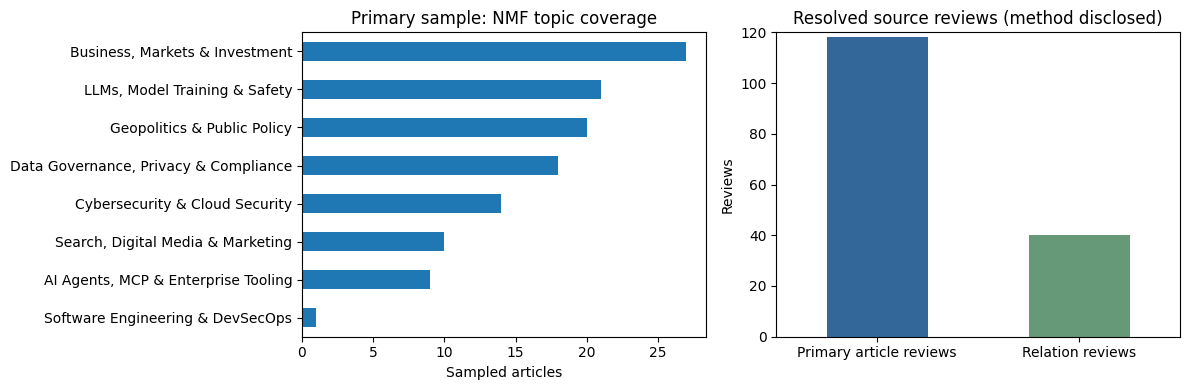

In [9]:
# Coverage and completion visualizations summarize current artifacts, not model performance.
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
main_topics = coverage.loc[(coverage["sample_group"] == "tagged_stratified") &
                          (coverage["dimension"] == "nmf_topic")].copy()
main_topics.set_index("value")["sample_count"].sort_values().plot.barh(ax=axes[0])
axes[0].set_title("Primary sample: NMF topic coverage")
axes[0].set_xlabel("Sampled articles")
axes[0].set_ylabel("")
progress = pd.Series({"Primary article reviews": int(main_progress["resolved"]),
                      "Relation reviews": manifest["counts"]["relation_reviews_resolved"]})
progress.plot.bar(ax=axes[1], color=["#336699", "#669977"])
axes[1].set_ylim(0, max(ARTICLE_SAMPLE_SIZE, RELATION_SAMPLE_SIZE))
axes[1].set_title("Resolved source reviews (method disclosed)")
axes[1].set_ylabel("Reviews")
axes[1].tick_params(axis="x", rotation=0)
fig.tight_layout()
fig.savefig(OUTPUT_DIR / "validation_overview.png", dpi=130, bbox_inches="tight")
plt.show()


In [10]:
# Summarize the actual attributed assessments and expose the remaining scope decisions.
all_article_counts = article_review["relevance_verdict"].value_counts()
relation_counts = relation_review["relation_verdict"].value_counts()
followup = article_review.loc[article_review["relevance_verdict"].eq("uncertain"),
    ["article_review_id", "record_id", "sample_group", "title", "review_method", "review_notes", "review_evidence"]]
display(followup)
display(relation_review.groupby(["review_selection", "relation_verdict"]).size().unstack(fill_value=0))
low, high = main_progress["weighted_relevance_min"], main_progress["weighted_relevance_max"]
display(Markdown(
    f"**Source-review findings:** all **{len(article_review)} articles** and **{len(relation_review)} relations** "
    f"have attributed assessments. Articles: **{int(all_article_counts.get('relevant', 0))} relevant**, "
    f"**{int(all_article_counts.get('irrelevant', 0))} irrelevant**, "
    f"**{int(all_article_counts.get('uncertain', 0))} uncertain**. "
    f"The primary stratified sample has an AI-assessed weighted relevance range of **{low:.1%}–{high:.1%}** "
    f"when its uncertain labels are assigned to either extreme. This is not a confidence interval or human-ground-truth precision. "
    f"Relations: **{int(relation_counts.get('supported', 0))} supported**, "
    f"**{int(relation_counts.get('weak', 0))} weak**, **{int(relation_counts.get('incorrect', 0))} incorrect**. "
    f"Only **{len(semantic_facts)}** supported, technically eligible source assertions enter the graph."
))


,article_review_id,record_id,sample_group,title,review_method,review_notes,review_evidence
19,8ddfdb2aa76693be9cd26fd5,104521,stage2_candidates,AI Architecture Design - Azure Architecture Ce...,ai_assisted,Broad AI architecture and service catalog incl...,Use the responsible AI dashboard for bias dete...
35,a227a5a89a7ff12125d2f548,150895,stage2_candidates,"The Download: How to run an LLM, and a history...",ai_assisted,Link-digest newsletter gives specific AI procu...,It’s preparing an executive order preventing c...
71,b7c46986bac3a4fed006eca6,48458,tagged_stratified,Growing Companies With Cutting-Edge Tech and B...,ai_assisted,Broad company innovation roundup contains one ...,We use a disciplined sandbox approach to stres...
107,2a8b18b9c6c79a5f7f4e0a11,71902,tagged_stratified,AI-Powered Scheduling in 2026: Transforming Ca...,ai_assisted,Scheduling promotion includes a short cluster ...,While AI can automate many aspects of scheduli...


relation_verdict,incorrect,supported,weak
review_selection,,,
important,2,10,8
random_tail,3,13,4


**Source-review findings:** all **160 articles** and **40 relations** have attributed assessments. Articles: **88 relevant**, **68 irrelevant**, **4 uncertain**. The primary stratified sample has an AI-assessed weighted relevance range of **54.5%–56.3%** when its uncertain labels are assigned to either extreme. This is not a confidence interval or human-ground-truth precision. Relations: **23 supported**, **12 weak**, **5 incorrect**. Only **22** supported, technically eligible source assertions enter the graph.

## Response to the Stage 1 feedback

This supplement implements the three requested checks using the existing Stage 1 outputs.

| Feedback point | Implemented evidence | Interpretation |
|---|---|---|
| Validate a sample of the selected Governance articles independently of their tags | Stratified source review of 120 originally selected articles, with verdicts, exact quotes, rationales and review-method attribution; topic-level diagnostics | The original tags are weak labels. Broad NMF topics describe vocabulary within that selected corpus; they do not establish Governance relevance or justify excluding an entire topic. The additional 40 Stage 2 candidates are a separate diagnostic. |
| Validate important graph edges and address incorrect or weakly supported claims | Review of 20 important and 20 randomly selected semantic edges; exact text alignment, schema, direction and source-date checks; individual inclusion/exclusion reasons | Supported statements retain their source evidence. Weak, incorrect and unreviewed semantic edges are excluded from factual retrieval. A source-supported statement may still be outside the topic scope. |
| Check reliable linkage between the co-occurrence and semantic-relation graphs for retrieval | Shared typed identifiers, explicit alias rules, reported type conflicts, a dated entity/article index and a source-retrieval demonstration | Co-occurrence remains an association. Semantic evidence stays attached to its source article. Low-frequency relation-only nodes are retained, while ambiguous cross-type identities are kept separate. |

The reviews are explicitly **AI-assisted**, with uncertain cases preserved. These checks document the reliability and limits of the available artifacts; they do not certify every article, every edge, or a retrieval-quality improvement. Subsequent Stage 3 work should use these distinctions when selecting passages and evidence.

The scope of this feedback response is the sampled validation, its interpretation and the graph-linkage check. Filter redesign, further model training and implementation of the RAG system are separate tasks.


## Interpretation, limitations and contributions

The computed tables above supersede the original assumption that every nonmissing extraction offset proves exact grounding. The supplementary article sample makes the original tag-based filter testable; it does not turn NMF clusters or Stage 2 predictions into independent labels. The graph handoff makes evidence retrieval reproducible while keeping associations and explicit claims separate.

This notebook is an evidence-quality preparation step. Stage 3 must still construct and manually review its Q&A set, compare text-only and graph-enhanced retrieval/answers, and evaluate one enhancement. No retrieval improvement is inferred from graph connectivity alone.

**AI-assisted review:** the user requested that Codex read the sampled sources and supply evidence-backed judgments. `review_method`, reviewer identity, date, exact quotes and rationale disclose this origin. Uncertain cases remain explicitly unresolved. Humans can inspect the source packets and replace individual decisions by recording `review_method="human"`, their identity, date, verdict and rationale. The original AI review records remain archived as JSONL. The 40 candidate decisions remain a separate diagnostic. The low primary-sample relevance is reported as a limitation; this feedback supplement does not claim to have validated all remaining articles.

**AI-tool disclosure:** ChatGPT / Codex implemented the workflow and performed the explicitly labelled AI-assisted article and relation source reviews at the user's request. No AI decision is represented as human review. This provides a source-based second assessment of the original weak tags and Gemini-extracted relations; it does not create an independently annotated human benchmark. The Stage 3 Q&A dataset still requires the manual review specified in the assignment.

**Contribution:** Supplementary implementation prepared with Codex at Henrik Szent-Ivany's request. Actual reviewers are recorded per decision rather than inferred from notebook authorship.
